# DM2583 · Group 5 · Constrained Flow Matching for vehicle trajectories
Fuad Mammadov, Gala Flores García, Harshit Poddar

**Version 2 (7 Oct).** What changed compared with version 1 and with the proposal:
- **Training:** 400 epochs instead of 150, with a learning rate that slowly goes down to 0 (cosine schedule). The paths of the plain model are about 2x smoother (jerk p95 15 → about 7 m/s³). Models are saved as `model_v2_seed*.pt`, so the old ones are never loaded by mistake.
- **Drivable area:** observed car centre positions grown by 0.8 m (proposal: 1.5 m). The smallest growth that still keeps 100% of real test paths on the road.
- **Projection Π:** the proposal's version (jump to the nearest road cell, then clip speed and acceleration, 3 times) did not work: the jumps made sharp corners, so the paths broke the acceleration rule instead (84% → 86% feasible only). New Π: find the path closest to the generated one that breaks no rule (1000 small optimisation steps), then one pass of speed/acceleration clipping. C uses 50 steps at each of the 50 sampling steps, D uses 1000 steps once.
- **Strategy B:** λ = 0.3, 1, 3 and 10, chosen on the validation set.
- **Experiment cell** saves after every run. If Colab disconnects, run it again: finished runs are skipped.

## 1 · Setup


In [1]:
from google.colab import drive
drive.mount("/content/drive")

PROJECT = "/content/drive/MyDrive/Group 5 - Big Data/DM2583_project/"
DATA = PROJECT + "data_processed/"
RAW = PROJECT + "raw/"
OUTPUTS = PROJECT + "outputs/"

import os
os.makedirs(OUTPUTS, exist_ok=True)
print(os.listdir(DATA))

Mounted at /content/drive
['train.npz', 'val.npz', 'test.npz', 'road_grid.npz']


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

device = "cuda" if torch.cuda.is_available() else "cpu"
print("running on:", device)

DT = 0.2       # seconds between points
H = 15         # history points (3 s)
F = 30         # future points (6 s) -> one sample = 30 x 2 = 60 numbers
V_MAX = 15.0   # m/s
A_MAX = 6.0    # m/s^2
TOL = 1e-3     # tiny tolerance when we check rules (rounding errors)

running on: cpu


In [3]:
train = dict(np.load(DATA + "train.npz"))
val = dict(np.load(DATA + "val.npz"))
test = dict(np.load(DATA + "test.npz"))
road_file = np.load(DATA + "road_grid.npz")

print("train:", len(train["fut_veh"]), "| val:", len(val["fut_veh"]), "| test:", len(test["fut_veh"]))

train: 8882 | val: 2944 | test: 2714


## 2 · Look at the data

In [4]:
rec_meta = pd.read_csv(RAW + "18_recordingMeta.csv")
image = plt.imread(RAW + "18_background.png")
metres_per_pixel = rec_meta["orthoPxToMeter"][0] * 12
height, width = image.shape[:2]
EXTENT = [0, width * metres_per_pixel, -height * metres_per_pixel, 0]

def draw_map(ax):
    ax.imshow(image, extent=EXTENT)
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")

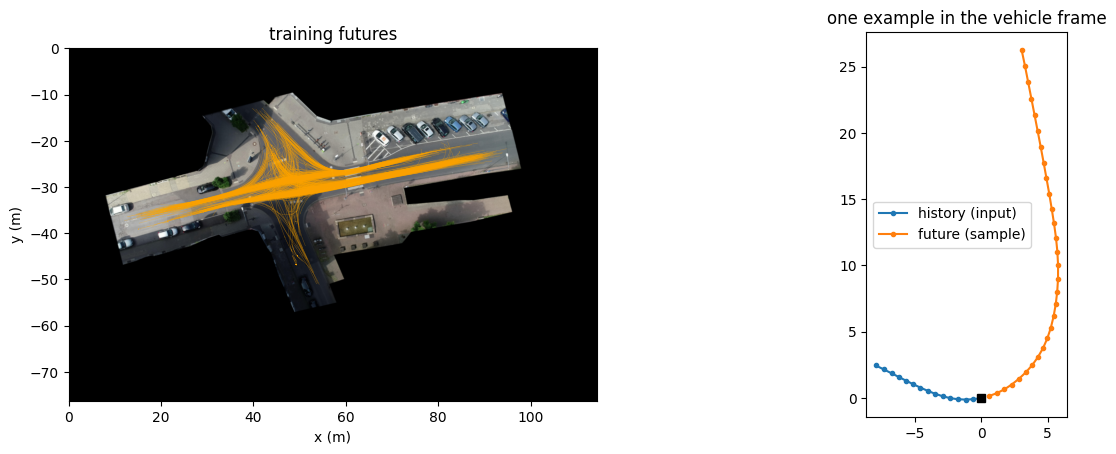

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

draw_map(axes[0])
for path in train["fut_map"][::5]:          # every 5th training future
    axes[0].plot(path[:, 0], path[:, 1], color="orange", linewidth=0.4, alpha=0.3)
axes[0].set_title("training futures")

i = 165                                      # one test example
axes[1].plot(test["hist_veh"][i, :, 0], test["hist_veh"][i, :, 1], "o-", color="tab:blue", markersize=3, label="history (input)")
axes[1].plot(test["fut_veh"][i, :, 0], test["fut_veh"][i, :, 1], "o-", color="tab:orange", markersize=3, label="future (sample)")
axes[1].plot(0, 0, "ks")
axes[1].set_aspect("equal")
axes[1].legend()
axes[1].set_title("one example in the vehicle frame")
plt.show()

## 3 · Flow Matching model

In [6]:
def to_steps(fut_veh):
    # positions (N, 30, 2) -> steps (N, 30, 2): how far the car moves in each 0.2 s
    start = np.zeros_like(fut_veh[:, :1])                         # the car starts at (0, 0)
    return np.diff(np.concatenate([start, fut_veh], axis=1), axis=1)

def flat(a):
    return a.reshape(len(a), -1)       # (N, 30, 2) -> (N, 60)

x_train = flat(to_steps(train["fut_veh"]))   # what we generate: 60 numbers
c_train = flat(train["hist_veh"])            # the condition: 30 numbers

# mean and spread, from TRAIN only
X_MEAN, X_STD = x_train.mean(axis=0), x_train.std(axis=0) + 1e-6
C_MEAN, C_STD = c_train.mean(axis=0), c_train.std(axis=0) + 1e-6

def prepare(split):
    x = (flat(to_steps(split["fut_veh"])) - X_MEAN) / X_STD
    c = (flat(split["hist_veh"]) - C_MEAN) / C_STD
    return torch.tensor(x, dtype=torch.float32, device=device), torch.tensor(c, dtype=torch.float32, device=device)

x_tr, c_tr = prepare(train)
x_va, c_va = prepare(val)
x_te, c_te = prepare(test)
print(x_tr.shape, c_tr.shape)

torch.Size([8882, 60]) torch.Size([8882, 30])


In [7]:
class FlowModel(nn.Module):
    def __init__(self, hidden=512):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(60 + 30 + 16, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 60),
        )

    def forward(self, x_t, t, c):
        # turn the single number t into 16 wave values, so the network can "read" time easily
        freqs = torch.arange(1, 9, device=t.device) * np.pi
        t_features = torch.cat([torch.sin(t[:, None] * freqs), torch.cos(t[:, None] * freqs)], dim=1)
        return self.net(torch.cat([x_t, c, t_features], dim=1))

model = FlowModel().to(device)
print("number of parameters:", sum(p.numel() for p in model.parameters()))

number of parameters: 610876


In [8]:
def fm_loss(model, x1, c):
    x0 = torch.randn_like(x1)                       # noise
    t = torch.rand(len(x1), device=device)          # a random time for every example
    x_t = (1 - t[:, None]) * x0 + t[:, None] * x1   # point on the straight line
    target = x1 - x0                                 # direction of the line
    prediction = model(x_t, t, c)
    return ((prediction - target) ** 2).mean()      # mean squared error

def train_model(seed, epochs=400, batch_size=256):
    torch.manual_seed(seed)
    model = FlowModel().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    batches_per_epoch = (len(x_tr) + batch_size - 1) // batch_size
    # cosine schedule: the learning rate goes smoothly from 1e-3 down to 0 at the end of training.
    # Small last steps = the model settles down = smoother paths.
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs * batches_per_epoch)
    val_losses = []
    for epoch in range(epochs):
        shuffled = torch.randperm(len(x_tr), device=device)     # shuffle
        for start in range(0, len(x_tr), batch_size):
            batch = shuffled[start:start + batch_size]
            loss = fm_loss(model, x_tr[batch], c_tr[batch])
            optimizer.zero_grad()    # forget old gradients
            loss.backward()          # compute new gradients
            optimizer.step()         # change the weights a little
            scheduler.step()         # make the learning rate a bit smaller
        with torch.no_grad():
            val_losses.append(fm_loss(model, x_va, c_va).item())
        if epoch % 50 == 0 or epoch == epochs - 1:
            print(f"epoch {epoch}: val loss {val_losses[-1]:.3f}")
    return model, val_losses

In [9]:
def get_model(seed):
    path = OUTPUTS + f"model_v2_seed{seed}.pt"     # v2 = 400 epochs + cosine
    model = FlowModel().to(device)
    if os.path.exists(path):
        model.load_state_dict(torch.load(path, map_location=device))
        print("loaded", path)
    else:
        model, val_losses = train_model(seed)
        torch.save(model.state_dict(), path)
        plt.plot(val_losses)
        plt.xlabel("epoch"); plt.ylabel("validation loss"); plt.title(f"training, seed {seed}")
        plt.savefig(OUTPUTS + f"loss_v2_seed{seed}.png", dpi=150, bbox_inches="tight")
        plt.show()
    model.eval()
    return model

model = get_model(0)

loaded /content/drive/MyDrive/Group 5 - Big Data/DM2583_project/outputs/model_v2_seed0.pt


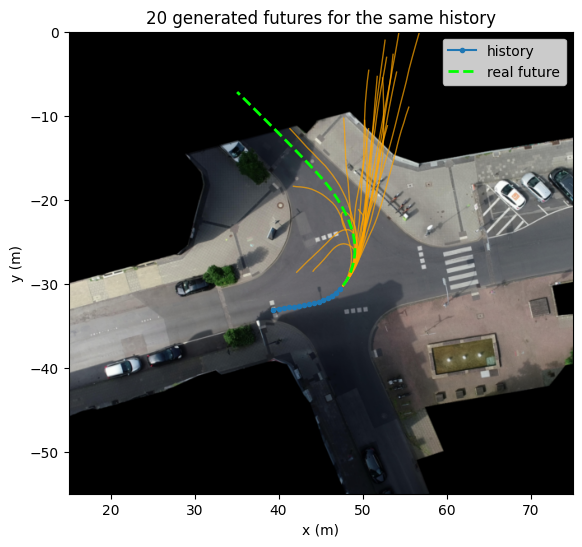

In [10]:
X_MEAN_T = torch.tensor(X_MEAN, dtype=torch.float32, device=device)
X_STD_T = torch.tensor(X_STD, dtype=torch.float32, device=device)

def to_map(x, origin, yaw):
    # normalised steps (N, 60) -> positions on the map (N, 30, 2)
    steps = (x * X_STD_T + X_MEAN_T).reshape(-1, F, 2)
    pos = torch.cumsum(steps, dim=1)                     # add up the steps
    c, s = torch.cos(yaw)[:, None], torch.sin(yaw)[:, None]
    map_x = c * pos[..., 0] - s * pos[..., 1] + origin[:, None, 0]
    map_y = s * pos[..., 0] + c * pos[..., 1] + origin[:, None, 1]
    return torch.stack([map_x, map_y], dim=-1)

def sample_plain(model, c, steps=50):
    x = torch.randn(len(c), 60, device=device)           # start: noise
    for k in range(steps):
        t = torch.full((len(c),), k / steps, device=device)
        with torch.no_grad():
            x = x + (1 / steps) * model(x, t, c)          # small step in the predicted direction
    return x

def tensors_for(i, n):
    # condition, origin, yaw and p0 of test example i, repeated n times
    c = c_te[i:i + 1].repeat(n, 1)
    origin = torch.tensor(test["origin"][i:i + 1], device=device).repeat(n, 1)
    yaw = torch.tensor(test["yaw"][i:i + 1], device=device).repeat(n)
    p0 = torch.tensor(test["hist_map"][i:i + 1, -1], device=device).repeat(n, 1)
    return c, origin, yaw, p0

i = 165
c, origin, yaw, p0 = tensors_for(i, 20)
paths = to_map(sample_plain(model, c), origin, yaw).cpu().numpy()

fig, ax = plt.subplots(figsize=(7, 6))
draw_map(ax)
ax.plot(test["hist_map"][i, :, 0], test["hist_map"][i, :, 1], "o-", color="tab:blue", markersize=3, label="history")
for path in paths:
    ax.plot(path[:, 0], path[:, 1], color="orange", linewidth=1, alpha=0.7)
ax.plot(test["fut_map"][i, :, 0], test["fut_map"][i, :, 1], "--", color="lime", linewidth=2, label="real future")
ax.set_xlim(15, 75); ax.set_ylim(-55, 0)
ax.legend()
ax.set_title("20 generated futures for the same history")
plt.savefig(OUTPUTS + "first_samples.png", dpi=150, bbox_inches="tight")
plt.show()

## 4 · Rules and projection


In [11]:
road_distance_grid = torch.tensor(road_file["distance"], device=device)
road_mask = road_file["road"]
X0, Y0, CELL = float(road_file["x0"]), float(road_file["y0"]), float(road_file["cell"])
N_ROWS, N_COLS = road_mask.shape

def road_distance(points):
    # D(p) for points (..., 2). Mixes the 4 nearest grid values (bilinear), so it changes smoothly.
    col = ((points[..., 0] - X0) / CELL).clamp(0, N_COLS - 1.001)
    row = ((points[..., 1] - Y0) / CELL).clamp(0, N_ROWS - 1.001)
    c0, r0 = col.floor().long(), row.floor().long()
    wc, wr = col - c0, row - r0                  # how far we are between grid nodes (0 to 1)
    top = (1 - wc) * road_distance_grid[r0, c0] + wc * road_distance_grid[r0, c0 + 1]
    bottom = (1 - wc) * road_distance_grid[r0 + 1, c0] + wc * road_distance_grid[r0 + 1, c0 + 1]
    return (1 - wr) * top + wr * bottom

In [12]:
def length(v):
    # length of 2D vectors. The tiny 1e-9 avoids a division by zero in the gradient at length 0.
    return torch.sqrt((v ** 2).sum(dim=-1) + 1e-9)

def rule_values(fut_map, p0):
    # fut_map: (N, 30, 2), p0: (N, 2). Returns g_road (N,30), g_speed (N,30), g_acc (N,29). g <= 0 means OK.
    p = torch.cat([p0[:, None, :], fut_map], dim=1)
    g_road = road_distance(fut_map)
    g_speed = length(p[:, 1:] - p[:, :-1]) / DT - V_MAX
    g_acc = length(p[:, 2:] - 2 * p[:, 1:-1] + p[:, :-2]) / DT**2 - A_MAX
    return g_road, g_speed, g_acc

def is_feasible(fut_map, p0):
    g_road, g_speed, g_acc = rule_values(fut_map, p0)
    return (g_road <= TOL).all(dim=1) & (g_speed <= TOL).all(dim=1) & (g_acc <= TOL).all(dim=1)

def penalty(fut_map, p0):
    # P = sum of (how much a rule is broken)^2. It is 0 for a feasible path.
    g_road, g_speed, g_acc = rule_values(fut_map, p0)
    return (torch.relu(g_road) ** 2).sum(dim=1) + (torch.relu(g_speed) ** 2).sum(dim=1) + (torch.relu(g_acc) ** 2).sum(dim=1)

In [13]:
def fix_speed_and_acceleration(p, p0):
    # walk along the path from p0 and limit every step
    new_points = []
    before, last = None, p0
    for k in range(F):
        step = p[:, k] - last
        if before is not None:
            same_speed_step = last - before                  # the step if the car kept its velocity
            change = step - same_speed_step                  # how much the velocity changes
            limit = A_MAX * DT**2
            size = length(change)[:, None]
            change = torch.where(size > limit, change * limit / size, change)    # shorten if too big
            step = same_speed_step + change
        limit = V_MAX * DT
        size = length(step)[:, None]
        step = torch.where(size > limit, step * limit / size, step)              # shorten if too long
        new_point = last + step
        new_points.append(new_point)
        before, last = last, new_point
    return torch.stack(new_points, dim=1)

def project(fut_map, p0, iters=1000, lr=0.05, weight=100.0, margin=0.5):
    # find the path closest to fut_map that keeps the rules:
    # minimise  distance to the original path  +  weight * (how much rules are broken)^2
    target = fut_map.detach()
    with torch.enable_grad():                      # needed because step 7 calls this inside no_grad
        p = target.clone().requires_grad_(True)
        opt = torch.optim.Adam([p], lr=lr)
        for _ in range(iters):
            g_road, g_speed, g_acc = rule_values(p, p0)
            broken = ((torch.relu(g_road + margin) ** 2).sum(1)      # stay 0.5 m inside the road
                      + (torch.relu(g_speed + 0.2) ** 2).sum(1)
                      + (torch.relu(g_acc + 0.3) ** 2).sum(1))
            loss = ((p - target) ** 2).sum(dim=(1, 2)) + weight * broken
            opt.zero_grad(); loss.sum().backward(); opt.step()
    return fix_speed_and_acceleration(p.detach(), p0)              # last pass: speed and acc are guaranteed

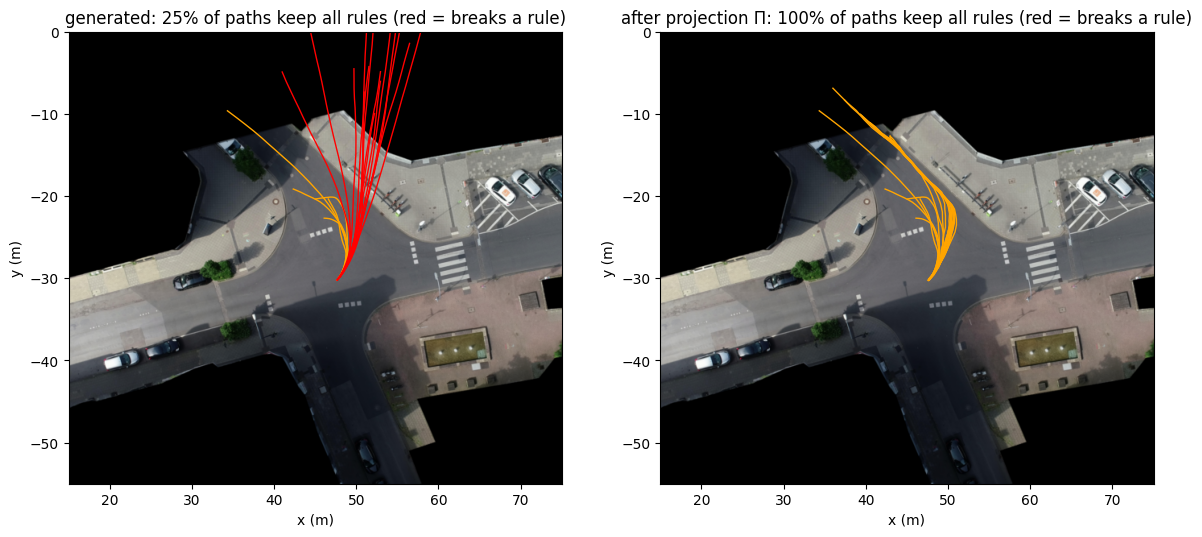

In [14]:
i = 165
c, origin, yaw, p0 = tensors_for(i, 20)
before = to_map(sample_plain(model, c), origin, yaw)
after = project(before, p0)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, paths, title in [(axes[0], before, "generated"), (axes[1], after, "after projection Π")]:
    ok = is_feasible(paths, p0).cpu().numpy()
    paths = paths.cpu().numpy()
    draw_map(ax)
    for k in range(len(paths)):
        ax.plot(paths[k, :, 0], paths[k, :, 1], color="orange" if ok[k] else "red", linewidth=1)
    ax.set_xlim(15, 75); ax.set_ylim(-55, 0)
    ax.set_title(f"{title}: {ok.mean():.0%} of paths keep all rules (red = breaks a rule)")
plt.savefig(OUTPUTS + "projection.png", dpi=150, bbox_inches="tight")
plt.show()

## 5 · Four strategies

In [15]:
def to_veh_steps(p_map, origin, yaw):
    # the opposite of to_map: map positions (N, 30, 2) -> normalised steps (N, 60)
    c, s = torch.cos(yaw)[:, None], torch.sin(yaw)[:, None]
    dx = p_map[..., 0] - origin[:, None, 0]
    dy = p_map[..., 1] - origin[:, None, 1]
    pos = torch.stack([c * dx + s * dy, -s * dx + c * dy], dim=-1)
    steps = torch.diff(pos, dim=1, prepend=torch.zeros_like(pos[:, :1]))
    return (steps.reshape(-1, 60) - X_MEAN_T) / X_STD_T

def sample(model, c, origin, yaw, p0, strategy="A", lam=1.0, steps=50, seed=0, keep_frames=False):
    torch.manual_seed(seed)
    x = torch.randn(len(c), 60, device=device)
    frames = []
    for k in range(steps):
        t = k / steps
        with torch.no_grad():
            v = model(x, torch.full((len(c),), t, device=device), c)
        x1_guess = x + (1 - t) * v           # clean guess: where we land if we jump to the end
        x0_guess = x - t * v                 # where we came from

        if strategy == "B":
            # gradient of the penalty: which way makes the rules break more. We go the other way.
            x1_guess = x1_guess.detach().requires_grad_(True)
            P = penalty(to_map(x1_guess, origin, yaw), p0).sum()
            grad = torch.autograd.grad(P, x1_guess)[0]
            size = grad.norm(dim=1, keepdim=True)
            grad = torch.where(size > 1, grad / size, grad)      # cap the push at length 1
            v = v - lam * grad

        if strategy == "C":
            repaired = to_veh_steps(project(to_map(x1_guess, origin, yaw), p0, iters=50), origin, yaw)
            x = (1 - t) * x0_guess + t * repaired                 # move the current point onto the repaired line
            v = repaired - x0_guess                               # and head for the repaired path

        x = x + (1 / steps) * v
        if keep_frames:
            frames.append(to_map(x.detach(), origin, yaw).cpu().numpy())

    with torch.no_grad():
        paths = to_map(x, origin, yaw)
        if strategy == "D":
            paths = project(paths, p0)
    if keep_frames:
        return paths, frames
    return paths

In [16]:
n = 500
c = c_te[:n]
origin = torch.tensor(test["origin"][:n], device=device)
yaw = torch.tensor(test["yaw"][:n], device=device)
p0 = torch.tensor(test["hist_map"][:n, -1], device=device)

for strategy in ["A", "B", "C", "D"]:
    paths = sample(model, c, origin, yaw, p0, strategy=strategy, lam=1.0)
    print(f"{strategy}: {is_feasible(paths, p0).float().mean():.1%} of paths keep all rules")

A: 68.8% of paths keep all rules
B: 79.2% of paths keep all rules
C: 99.8% of paths keep all rules
D: 98.0% of paths keep all rules


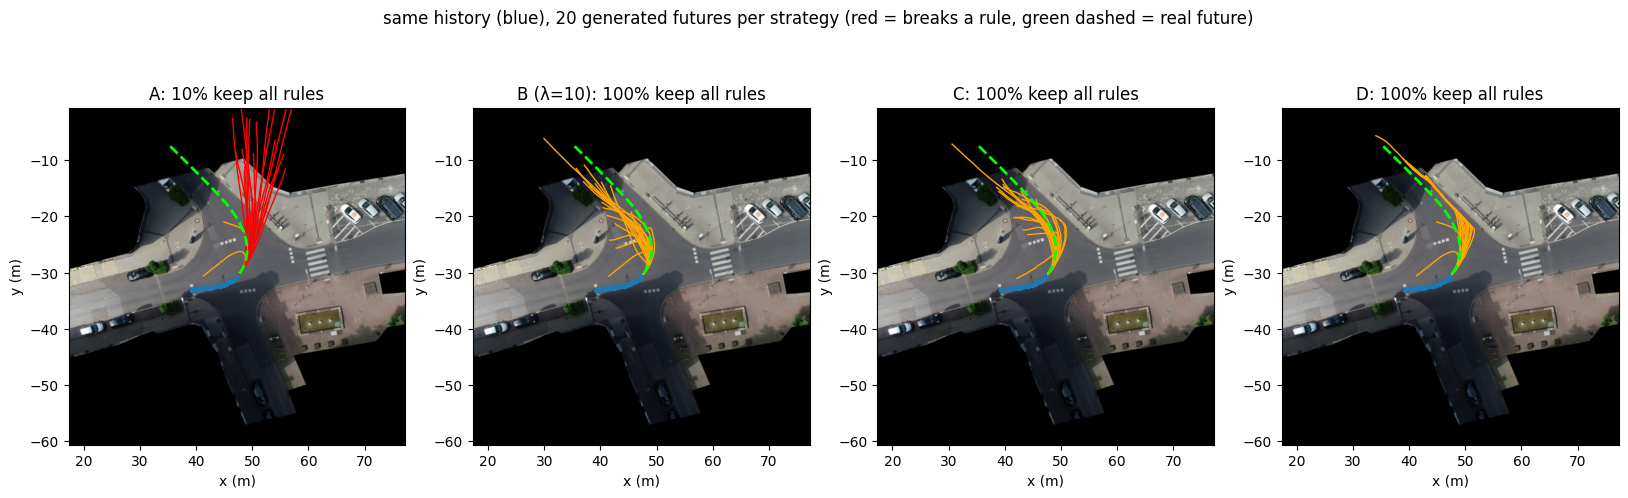

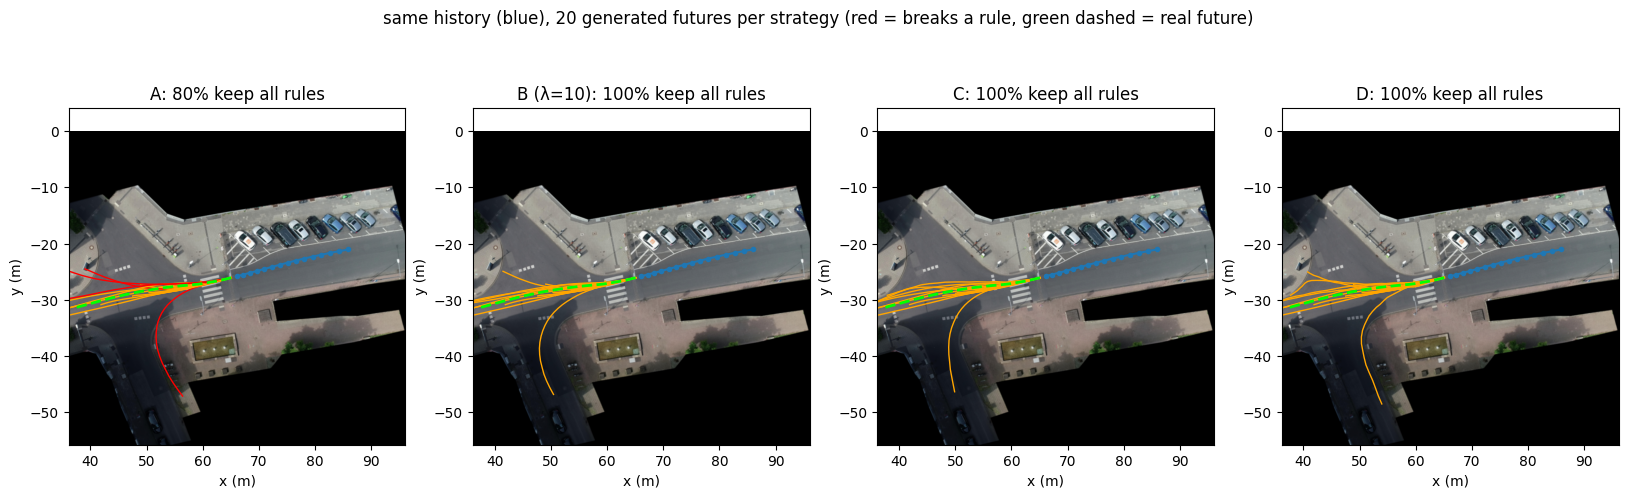

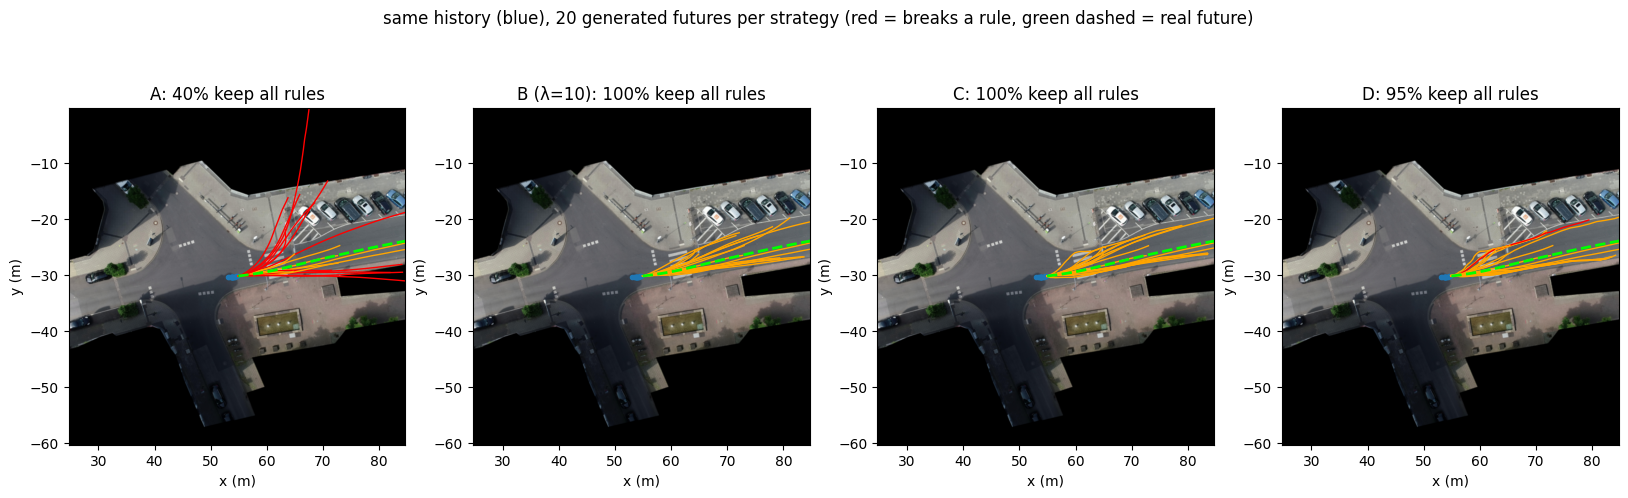

In [17]:
def demo_figure(i, n=20, lam=10.0, save=None):
    c, origin, yaw, p0 = tensors_for(i, n)
    fig, axes = plt.subplots(1, 4, figsize=(20, 5.5))
    for ax, strategy in zip(axes, ["A", "B", "C", "D"]):
        paths = sample(model, c, origin, yaw, p0, strategy=strategy, lam=lam, seed=1)
        ok = is_feasible(paths, p0).cpu().numpy()
        paths = paths.cpu().numpy()
        draw_map(ax)
        ax.plot(test["hist_map"][i, :, 0], test["hist_map"][i, :, 1], "o-", color="tab:blue", markersize=3)
        for k in range(n):
            ax.plot(paths[k, :, 0], paths[k, :, 1], color="orange" if ok[k] else "red", linewidth=1)
        ax.plot(test["fut_map"][i, :, 0], test["fut_map"][i, :, 1], "--", color="lime", linewidth=2)   # what the car really did
        centre = test["hist_map"][i, -1]
        ax.set_xlim(centre[0] - 30, centre[0] + 30)
        ax.set_ylim(centre[1] - 30, centre[1] + 30)
        name = f"B (λ={lam:g})" if strategy == "B" else strategy
        ax.set_title(f"{name}: {ok.mean():.0%} keep all rules")
    plt.suptitle("same history (blue), 20 generated futures per strategy (red = breaks a rule, green dashed = real future)")
    if save:
        plt.savefig(save, dpi=150, bbox_inches="tight")
    plt.show()

demo_figure(165, save=OUTPUTS + "demo_165.png")
demo_figure(100, save=OUTPUTS + "demo_100.png")
demo_figure(1000, save=OUTPUTS + "demo_1000.png")

## 6 · Metrics

In [18]:
from scipy.stats import wasserstein_distance

def sliced_wasserstein(a, b, n_directions=200):
    # a, b: (N, 60). Look at both clouds from 200 random directions and compare the sorted values.
    rng = np.random.default_rng(0)
    directions = rng.normal(size=(a.shape[1], n_directions))
    directions /= np.linalg.norm(directions, axis=0)
    a_sorted = np.sort(a @ directions, axis=0)
    b_sorted = np.sort(b @ directions, axis=0)
    return np.abs(a_sorted - b_sorted).mean()

def to_vehicle_np(p_map, origin, yaw):
    # numpy version: map points (N, 30, 2) -> vehicle frame (N, 30, 2)
    c, s = np.cos(yaw)[:, None], np.sin(yaw)[:, None]
    dx = p_map[..., 0] - origin[:, None, 0]
    dy = p_map[..., 1] - origin[:, None, 1]
    return np.stack([c * dx + s * dy, -s * dx + c * dy], axis=-1)

def manoeuvre_shares(fut_veh):
    end = fut_veh[:, -1]                                        # end point seen from the car
    angle = np.degrees(np.arctan2(end[:, 1], end[:, 0]))
    label = np.where(angle > 30, "left", np.where(angle < -30, "right", "straight"))
    label = np.where(np.linalg.norm(end, axis=1) < 2, "stopped", label)
    return {name: np.mean(label == name) for name in ["left", "straight", "right", "stopped"]}

In [19]:
def evaluate(paths, real, p0, origin, yaw):
    # paths, real: (N, 30, 2) torch tensors in map coordinates, for the same N histories
    g_road, g_speed, g_acc = rule_values(paths, p0)
    gen = paths.cpu().numpy()
    real_np = real.cpu().numpy()
    o, y = origin.cpu().numpy(), yaw.cpu().numpy()
    gen_veh = to_vehicle_np(gen, o, y).reshape(len(gen), -1)
    real_veh = to_vehicle_np(real_np, o, y).reshape(len(gen), -1)

    # excess SWD: generated vs real, minus real vs real (two halves), same size
    half = len(gen) // 2
    swd_gen = sliced_wasserstein(gen_veh[:half], real_veh[half:2 * half])
    swd_real = sliced_wasserstein(real_veh[:half], real_veh[half:2 * half])

    jerk = np.linalg.norm(np.diff(gen, n=3, axis=1), axis=-1) / DT**3
    result = {
        "violation road (m)": torch.relu(g_road).mean().item(),
        "violation speed (m/s)": torch.relu(g_speed).mean().item(),
        "violation acc (m/s²)": torch.relu(g_acc).mean().item(),
        "on-surface rate": is_feasible(paths, p0).float().mean().item(),
        "excess SWD": swd_gen - swd_real,
        "road-edge W1 (m)": wasserstein_distance(road_distance(paths).cpu().numpy().ravel(),
                                                 road_distance(real).cpu().numpy().ravel()),
        "jerk p95 (m/s³)": np.percentile(jerk, 95),
    }
    for name, share in manoeuvre_shares(gen_veh.reshape(-1, F, 2)).items():
        result["share " + name] = share
    return result

def diversity(model, strategy, lam, n_histories=200, n_samples=20):
    # average distance (m) of 20 end points from their mean, for the same history
    idx = np.repeat(np.arange(n_histories), n_samples)        # 0,0,...,0,1,1,...,1,... (20 times each)
    c = c_te[idx]
    origin = torch.tensor(test["origin"][idx], device=device)
    yaw = torch.tensor(test["yaw"][idx], device=device)
    p0 = torch.tensor(test["hist_map"][idx, -1], device=device)
    ends = sample(model, c, origin, yaw, p0, strategy=strategy, lam=lam)[:, -1].cpu().numpy()
    ends = ends.reshape(n_histories, n_samples, 2)
    spread = np.linalg.norm(ends - ends.mean(axis=1, keepdims=True), axis=-1)
    return spread.mean()

In [20]:
N_EVAL = 2000
origin = torch.tensor(test["origin"][:N_EVAL], device=device)
yaw = torch.tensor(test["yaw"][:N_EVAL], device=device)
p0 = torch.tensor(test["hist_map"][:N_EVAL, -1], device=device)
real = torch.tensor(test["fut_map"][:N_EVAL], device=device)
c = c_te[:N_EVAL]

reference = evaluate(real, real, p0, origin, yaw)
pd.Series(reference).round(3)

,0
violation road (m),0.000
violation speed (m/s),0.000
violation acc (m/s²),0.000
on-surface rate,0.990
excess SWD,0.000
road-edge W1 (m),0.000
jerk p95 (m/s³),4.304
share left,0.120
share straight,0.716
share right,0.088


## 7 · Experiment

In [21]:
n = 500
c_v = c_va[:n]
origin_v = torch.tensor(val["origin"][:n], device=device)
yaw_v = torch.tensor(val["yaw"][:n], device=device)
p0_v = torch.tensor(val["hist_map"][:n, -1], device=device)

for lam in [0.1, 0.3, 1.0, 3.0, 10.0, 30.0]:
    paths = sample(model, c_v, origin_v, yaw_v, p0_v, strategy="B", lam=lam)
    print(f"λ = {lam}: {is_feasible(paths, p0_v).float().mean():.1%} keep all rules")

λ = 0.1: 72.6% keep all rules
λ = 0.3: 73.2% keep all rules
λ = 1.0: 83.0% keep all rules
λ = 3.0: 95.6% keep all rules
λ = 10.0: 99.8% keep all rules
λ = 30.0: 99.8% keep all rules


In [22]:
SEEDS = [0, 1, 2]
LAMBDAS = [0.3, 1.0, 3.0, 10.0]
RUNS = [("A", 0.0)] + [("B", lam) for lam in LAMBDAS] + [("C", 0.0), ("D", 0.0)]
RESULTS_FILE = OUTPUTS + "results_v2.csv"

# If Colab disconnects: just run this cell again. Finished runs are read from the file and skipped.
rows = pd.read_csv(RESULTS_FILE).to_dict("records") if os.path.exists(RESULTS_FILE) else []
done = {(r["strategy"], int(r["seed"])) for r in rows}

for seed in SEEDS:
    model_s = get_model(seed)                 # trains if not saved yet (about 5 min per seed)
    for strategy, lam in RUNS:
        name = strategy if strategy != "B" else f"B λ={lam}"
        if (name, seed) in done:
            print(f"seed {seed} | {name:9s} | already done, skipped")
            continue
        paths = sample(model_s, c, origin, yaw, p0, strategy=strategy, lam=lam, seed=seed)
        result = evaluate(paths, real, p0, origin, yaw)
        result["diversity (m)"] = diversity(model_s, strategy, lam)
        result["strategy"] = name
        result["seed"] = seed
        rows.append(result)
        pd.DataFrame(rows).to_csv(RESULTS_FILE, index=False)      # save after every run
        print(f"seed {seed} | {name:9s} | on-surface {result['on-surface rate']:.1%} | jerk {result['jerk p95 (m/s³)']:.1f} | diversity {result['diversity (m)']:.2f}")

results = pd.DataFrame(rows)
print(len(results), "runs saved (expect 21 = 3 seeds x 7 settings)")


loaded /content/drive/MyDrive/Group 5 - Big Data/DM2583_project/outputs/model_v2_seed0.pt
seed 0 | A         | already done, skipped
seed 0 | B λ=0.3   | already done, skipped
seed 0 | B λ=1.0   | already done, skipped
seed 0 | B λ=3.0   | already done, skipped
seed 0 | B λ=10.0  | already done, skipped
seed 0 | C         | already done, skipped
seed 0 | D         | already done, skipped
loaded /content/drive/MyDrive/Group 5 - Big Data/DM2583_project/outputs/model_v2_seed1.pt
seed 1 | A         | already done, skipped
seed 1 | B λ=0.3   | already done, skipped
seed 1 | B λ=1.0   | already done, skipped
seed 1 | B λ=3.0   | already done, skipped
seed 1 | B λ=10.0  | already done, skipped
seed 1 | C         | already done, skipped
seed 1 | D         | already done, skipped
loaded /content/drive/MyDrive/Group 5 - Big Data/DM2583_project/outputs/model_v2_seed2.pt
seed 2 | A         | already done, skipped
seed 2 | B λ=0.3   | already done, skipped
seed 2 | B λ=1.0   | already done, skipped

In [23]:
results = pd.read_csv(RESULTS_FILE)
order = ["A"] + [f"B λ={lam}" for lam in LAMBDAS] + ["C", "D"]
mean = results.groupby("strategy").mean(numeric_only=True).drop(columns="seed").loc[order]
std = results.groupby("strategy").std(numeric_only=True).drop(columns="seed").loc[order]

table = mean.round(3).astype(str) + " ± " + std.fillna(0).round(3).astype(str)
table.loc["real data"] = pd.Series(reference).round(3).astype(str)
table.T.to_csv(OUTPUTS + "results_table_v2.csv")       # for the report
table.T


strategy,A,B λ=0.3,B λ=1.0,B λ=3.0,B λ=10.0,C,D,real data
violation road (m),0.223 ± 0.011,0.181 ± 0.011,0.105 ± 0.011,0.019 ± 0.003,0.0 ± 0.0,0.001 ± 0.001,0.001 ± 0.0,0.0
violation speed (m/s),0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0
violation acc (m/s²),0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0
on-surface rate,0.719 ± 0.008,0.737 ± 0.008,0.811 ± 0.004,0.964 ± 0.003,0.999 ± 0.0,0.997 ± 0.001,0.987 ± 0.003,0.99
excess SWD,-0.019 ± 0.022,-0.035 ± 0.023,-0.057 ± 0.022,-0.058 ± 0.027,-0.028 ± 0.03,-0.027 ± 0.033,-0.047 ± 0.024,0.0
road-edge W1 (m),0.483 ± 0.022,0.432 ± 0.023,0.338 ± 0.024,0.229 ± 0.017,0.211 ± 0.013,0.173 ± 0.01,0.211 ± 0.011,0.0
jerk p95 (m/s³),6.926 ± 0.046,6.916 ± 0.046,6.887 ± 0.053,6.859 ± 0.051,6.935 ± 0.051,13.441 ± 0.783,36.984 ± 0.282,4.304
share left,0.101 ± 0.005,0.101 ± 0.005,0.097 ± 0.002,0.093 ± 0.004,0.086 ± 0.004,0.087 ± 0.005,0.088 ± 0.004,0.12
share straight,0.752 ± 0.005,0.753 ± 0.004,0.759 ± 0.004,0.767 ± 0.007,0.777 ± 0.004,0.778 ± 0.007,0.771 ± 0.007,0.716
share right,0.054 ± 0.002,0.054 ± 0.002,0.052 ± 0.002,0.047 ± 0.002,0.043 ± 0.001,0.041 ± 0.002,0.049 ± 0.002,0.088


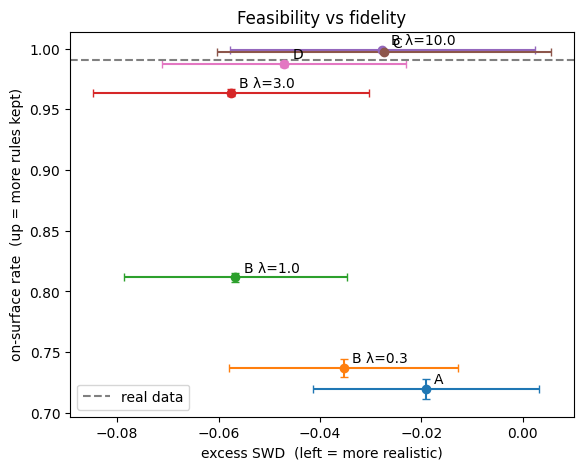

In [24]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for name in order:
    ax.errorbar(mean.loc[name, "excess SWD"], mean.loc[name, "on-surface rate"],
                xerr=std.loc[name, "excess SWD"], yerr=std.loc[name, "on-surface rate"], fmt="o", capsize=3)
    ax.annotate(name, (mean.loc[name, "excess SWD"], mean.loc[name, "on-surface rate"]),
                textcoords="offset points", xytext=(6, 4))
ax.axhline(reference["on-surface rate"], color="gray", linestyle="--", label="real data")
ax.set_xlabel("excess SWD  (left = more realistic)")
ax.set_ylabel("on-surface rate  (up = more rules kept)")
ax.legend()
ax.set_title("Feasibility vs fidelity")
plt.savefig(OUTPUTS + "tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()

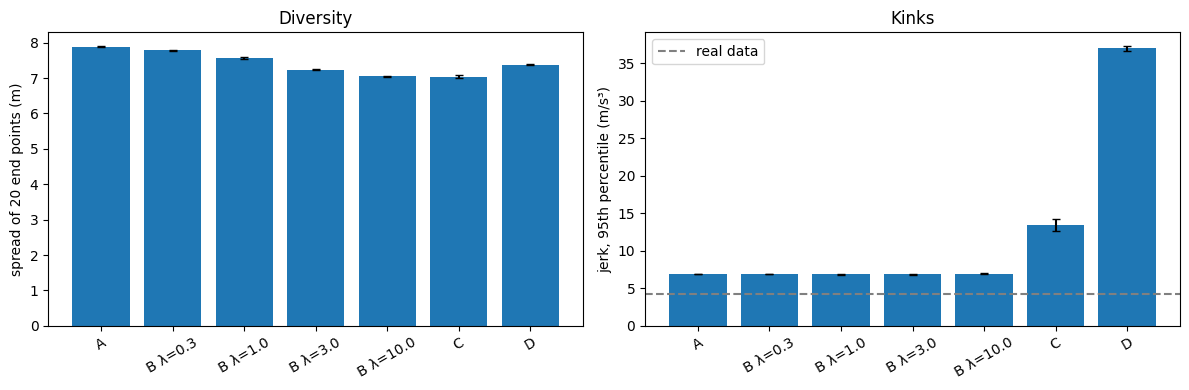

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(order, mean["diversity (m)"], yerr=std["diversity (m)"], capsize=3)
axes[0].set_ylabel("spread of 20 end points (m)")
axes[0].set_title("Diversity")
axes[1].bar(order, mean["jerk p95 (m/s³)"], yerr=std["jerk p95 (m/s³)"], capsize=3)
axes[1].axhline(reference["jerk p95 (m/s³)"], color="gray", linestyle="--", label="real data")
axes[1].set_ylabel("jerk, 95th percentile (m/s³)")
axes[1].set_title("Kinks")
axes[1].legend()
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(OUTPUTS + "diversity_and_jerk.png", dpi=150, bbox_inches="tight")
plt.show()

### Realism check: where do 2000 futures go?
The demo figures show one car. This shows all 2000 test cars at once: real futures vs generated ones (seed 0). Brighter = more points. If the generated picture looks like the real one, the traffic is realistic. A leaks into buildings; check whether C and D follow the real lanes, and whether D piles points up at the road edge.

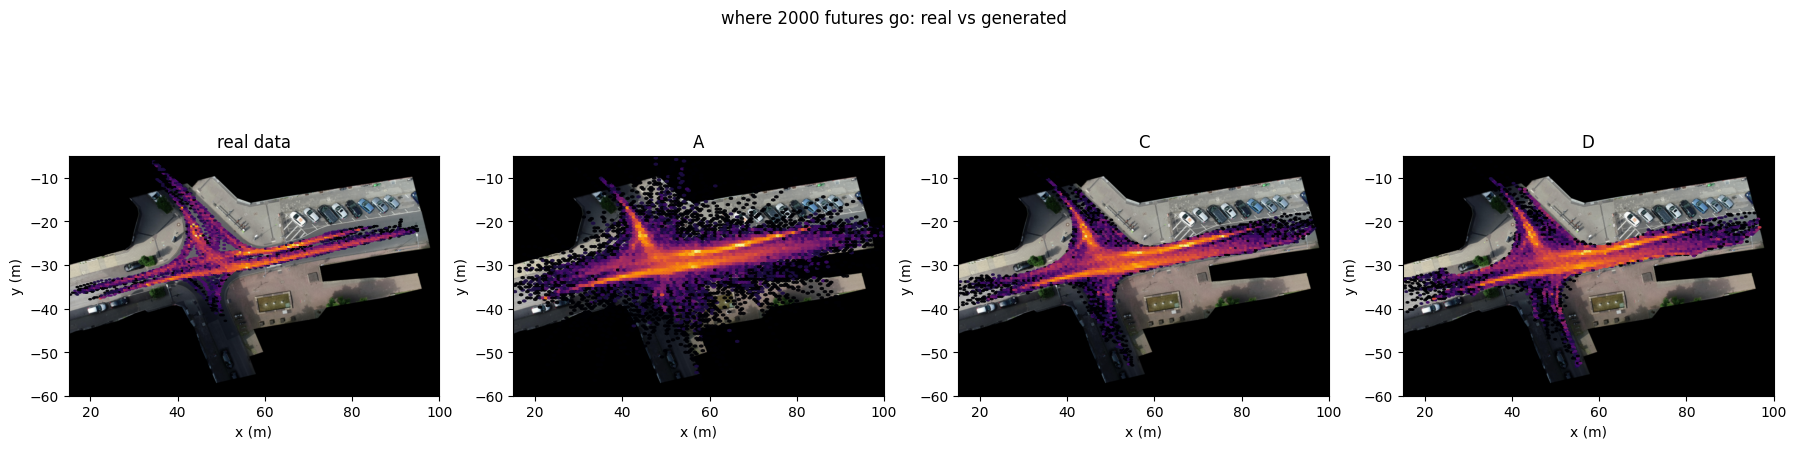

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
clouds = {"real data": real}
for s in ["A", "C", "D"]:
    clouds[s] = sample(model, c, origin, yaw, p0, strategy=s, seed=0)

for ax, (name, paths) in zip(axes, clouds.items()):
    pts = paths.cpu().numpy().reshape(-1, 2)
    draw_map(ax)
    ax.hexbin(pts[:, 0], pts[:, 1], gridsize=150, bins="log", cmap="inferno", mincnt=1, alpha=0.85)
    ax.set_xlim(15, 100); ax.set_ylim(-60, -5)
    ax.set_title(name)
plt.suptitle("where 2000 futures go: real vs generated")
plt.savefig(OUTPUTS + "density_real_vs_generated.png", dpi=150, bbox_inches="tight")
plt.show()


## 8 · Demo
Slider: pick a car and change λ for B. Then two GIFs that show the paths forming from noise (A and C).

In [29]:
from ipywidgets import interact_manual, IntSlider, FloatSlider

def live_demo(car=165, lam=10.0):
    demo_figure(car, lam=lam)

# Move the sliders, then click "Run Interact". Nothing is computed while you drag.
# Good cars to show: 165 (left turn), 100, 1000
interact_manual(live_demo,
                car=IntSlider(min=0, max=len(test["fut_veh"]) - 1, step=1, value=165),
                lam=FloatSlider(min=0.1, max=30, step=0.1, value=10.0))

interactive(children=(IntSlider(value=165, description='car', max=2713), FloatSlider(value=10.0, description='…

<function __main__.live_demo(car=165, lam=10.0)>

In [32]:
import os
from PIL import Image
from IPython.display import Image as ShowGif, display

def make_animation(i, strategy="A", n=20, lam=10.0, filename=None):
    c, origin, yaw, p0 = tensors_for(i, n)
    paths, frames = sample(model, c, origin, yaw, p0, strategy=strategy, lam=lam, keep_frames=True, seed=1)
    final = paths.cpu().numpy()                              # end result (for D: after the repair)
    centre = test["hist_map"][i, -1]
    name = f"B (λ={lam:g})" if strategy == "B" else strategy

    # the list of pictures: (paths, title, show real future?, how long to show it in ms)
    shots = []
    for k, f in enumerate(frames):
        wait = 800 if k == 0 else int(60 + 100 * k / len(frames))   # pause on the noise, then slow down towards the end
        shots.append((f, f"{name}: step {k + 1} of {len(frames)}", False, wait))
    if strategy == "D":                                      # D: slide smoothly from the raw paths to the repaired ones
        for w in np.linspace(0, 1, 21)[1:]:
            w = w * w * (3 - 2 * w)                          # ease in and out
            shots.append(((1 - w) * frames[-1] + w * final, f"{name}: repairing at the end", False, 120))
    shots.append((final, f"{name}: result", True, 3000))     # hold the result 3 s, with the real future

    fig, ax = plt.subplots(figsize=(6, 6), dpi=80)
    images, durations = [], []
    for p, title, show_real, wait in shots:
        ok = is_feasible(torch.tensor(p, device=device), p0).cpu().numpy()
        ax.clear()
        draw_map(ax)
        ax.plot(test["hist_map"][i, :, 0], test["hist_map"][i, :, 1], "o-", color="tab:blue", markersize=3)
        for path, good in zip(p, ok):
            ax.plot(path[:, 0], path[:, 1], color="orange" if good else "red", linewidth=1.2)
        if show_real:
            ax.plot(test["fut_map"][i, :, 0], test["fut_map"][i, :, 1], "--", color="lime", linewidth=2)
        ax.set_xlim(centre[0] - 30, centre[0] + 30)
        ax.set_ylim(centre[1] - 30, centre[1] + 30)
        ax.set_title(f"{title}   ({ok.mean():.0%} keep all rules)", fontsize=10)
        fig.canvas.draw()
        images.append(Image.fromarray(np.asarray(fig.canvas.buffer_rgba())[..., :3].copy()))
        durations.append(wait)
    plt.close(fig)

    result = images[-1]
    for w in [0.2, 0.4, 0.6, 0.8]:                           # fade back to the start, so the loop does not jump
        images.append(Image.blend(result, images[0], w))
        durations.append(80)

    filename = filename or OUTPUTS + f"flow_{strategy}_{i}.gif"
    images[0].save(filename, save_all=True, append_images=images[1:], duration=durations, loop=0)
    print(f"saved {filename}  ({os.path.getsize(filename) // 1024} KB)")
    display(ShowGif(filename=filename))                      # play it right here, to check

for strategy in ["A", "B", "C", "D"]:
    make_animation(165, strategy)

Output hidden; open in https://colab.research.google.com to view.